# Recipe: Your own density distribution

density_law = 'user' calls user_density_fn in src/user_density.f90 (by default a power law times a Gaussian clump in azimuth, parameters user_par). The image is convolved with a 0.3" beam. Edit src/user_density.f90 and run make for another density.

**Files:** `examples/clump_user_density.nml`, `src/user_density.f90`  
**Run time:** about 5 s  
**Manual:** Sect. 16.6 of `docs/manual/dms_manual.pdf`. The same code as a script: `python3 examples/recipes/user_clump.py`.

In [1]:
# Setup: this notebook lives in examples/recipes/ of the repository
import os, sys
if "REPO" not in globals():
    REPO = os.environ.get("DMS_REPO") or os.path.abspath(os.path.join("..", ".."))
sys.path.insert(0, os.path.join(REPO, "python"))      # use the DMS of this repository
os.chdir(REPO)                                        # input files and cache/ are relative to the root
import dms
import numpy as np
import matplotlib.pyplot as plt
print("DMS", dms.__version__)

DMS 2.2.1


870 micron: 9.58 mJy;  peak 0.578 mJy/arcsec^2


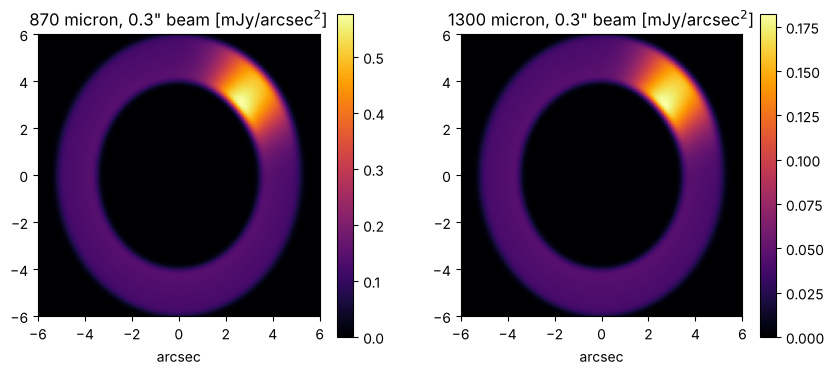

In [2]:
res = dms.Model.from_file("examples/clump_user_density.nml").run()
obs = res.image("thermal", observed=True, unit="mJy/arcsec2")
half = res.pixel_arcsec * obs.shape[-1] / 2
print(f"870 micron: {res.sed['thermal'][0] * 1e3:.2f} mJy;  peak {obs[0].max():.3f} mJy/arcsec^2")
fig, ax = plt.subplots(1, 2, figsize=(10, 4.2))
for j in range(2):
    p = ax[j].imshow(obs[j], origin="lower", cmap="inferno", extent=[-half, half, -half, half])
    ax[j].set_title(f"{res.wavelength[j]:g} micron, 0.3\" beam [mJy/arcsec$^2$]"); plt.colorbar(p, ax=ax[j])
    ax[j].set_xlabel("arcsec")
plt.show()

**Result.** 9.6 mJy at 870 µm. To use another density law, write it in `user_density_fn` in `src/user_density.f90`, then run `make` and `make python` and restart the kernel.